# 02. Профилирование качества данных (bronze)

Проверки по шести измерениям качества: уникальность, ссылочная целостность, полнота,
валидность, покрытие во времени, согласованность train/test.

Источник — `.parquet` из `data/bronze`. Все запросы идут через DuckDB поверх parquet
(без загрузки 125 млн строк в pandas); в pandas переводятся только небольшие результаты.

Ожидаемые колонки (как в исходном Kaggle-датасете):

| таблица | колонки |
|---|---|
| train | id, date, store_nbr, item_nbr, unit_sales, onpromotion |
| test | id, date, store_nbr, item_nbr, onpromotion |
| stores | store_nbr, city, state, type, cluster |
| items | item_nbr, family, class, perishable |
| transactions | date, store_nbr, transactions |
| oil | date, dcoilwtico |
| holidays_events | date, type, locale, locale_name, description, transferred |

## 0. Подготовка

In [1]:
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import pandas as pd

pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 200)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
BRONZE = ROOT / "data" / "bronze"

TABLES = ["train", "test", "stores", "items", "transactions", "oil", "holidays_events"]
DATED = {"train", "test", "transactions", "oil", "holidays_events"}


def parquet_source(name: str) -> str:
    """Файл <name>.parquet или каталог <name>/ с parquet-частями."""
    f = BRONZE / f"{name}.parquet"
    if f.is_file():
        return f.as_posix()
    d = BRONZE / name
    if d.is_dir():
        return (d / "**" / "*.parquet").as_posix()
    raise FileNotFoundError(f"Не найден parquet для таблицы {name!r} в {BRONZE}")


con = duckdb.connect()
con.execute("SET memory_limit = '6GB'")  # подстрой под свою машину
con.execute("SET preserve_insertion_order = false")

for t in TABLES:
    select = "SELECT * REPLACE (CAST(date AS DATE) AS date)" if t in DATED else "SELECT *"
    con.execute(f"CREATE OR REPLACE VIEW {t} AS {select} FROM read_parquet('{parquet_source(t)}')")


def q(sql: str) -> pd.DataFrame:
    return con.sql(sql).df()


def scalar(sql: str) -> int:
    """Первое значение первой строки (у DuckDBPyRelation в duckdb 2.x нет fetchone)."""
    return int(con.sql(sql).fetchall()[0][0])

### Схемы и размеры таблиц

In [2]:
q("""
SELECT table_name, column_name, data_type, is_nullable
FROM information_schema.columns
ORDER BY table_name, ordinal_position
""")

,table_name,column_name,data_type,is_nullable
0,holidays_events,date,DATE,YES
1,holidays_events,type,VARCHAR,YES
2,holidays_events,locale,VARCHAR,YES
3,holidays_events,locale_name,VARCHAR,YES
4,holidays_events,description,VARCHAR,YES
5,holidays_events,transferred,BOOLEAN,YES
6,items,item_nbr,INTEGER,YES
7,items,family,VARCHAR,YES
8,items,class,SMALLINT,YES
9,items,perishable,BOOLEAN,YES


In [3]:
q(" UNION ALL ".join(f"SELECT '{t}' AS table_name, COUNT(*) AS n_rows FROM {t}" for t in TABLES))

,table_name,n_rows
0,train,125497040
1,oil,1218
2,transactions,83488
3,holidays_events,350
4,test,3370464
5,items,4100
6,stores,54


In [4]:
# Диапазоны дат по таблицам с датой
q(
    " UNION ALL ".join(
        f"SELECT '{t}' AS table_name, MIN(date) AS min_date, MAX(date) AS max_date, "
        f"COUNT(DISTINCT date) AS n_dates FROM {t}"
        for t in sorted(DATED)
    )
)

,table_name,min_date,max_date,n_dates
0,holidays_events,2012-03-02,2017-12-26,312
1,oil,2013-01-01,2017-08-31,1218
2,test,2017-08-16,2017-08-31,16
3,train,2013-01-01,2017-08-15,1684
4,transactions,2013-01-01,2017-08-15,1682


## 1. Уникальность

### 1.1 Уникальный ключ (date, store_nbr) в transactions

Ожидание: 0 дубликатов и 0 NULL в ключевых колонках.

In [5]:
uk = q("""
SELECT
    COUNT(*)                                                   AS n_rows,
    COUNT(*) FILTER (WHERE date IS NULL OR store_nbr IS NULL)  AS n_null_key,
    (SELECT COUNT(*) FROM (SELECT DISTINCT date, store_nbr FROM transactions)) AS n_distinct_key
FROM transactions
""")
uk["n_duplicate_rows"] = uk["n_rows"] - uk["n_distinct_key"]
uk

,n_rows,n_null_key,n_distinct_key,n_duplicate_rows
0,83488,0,83488,0


In [6]:
# Сами дубликаты, если есть
q("""
SELECT date, store_nbr, COUNT(*) AS n, LIST(transactions) AS values
FROM transactions
GROUP BY date, store_nbr
HAVING COUNT(*) > 1
ORDER BY n DESC, date
LIMIT 50
""")

,date,store_nbr,n,values


### 1.2 holidays_events: кандидат в ключ и полные дубли строк

Сначала полные дубли (все колонки совпадают), затем — сколько дублей даёт каждый
набор колонок-кандидатов. Кандидат в ключ — минимальный набор с 0 дублей.

In [7]:
# Полные дубли строк
q("""
SELECT *, COUNT(*) AS n
FROM holidays_events
GROUP BY ALL
HAVING COUNT(*) > 1
ORDER BY date
""")

,date,type,locale,locale_name,description,transferred,n


In [8]:
CANDIDATES = [
    ["date"],
    ["date", "locale_name"],
    ["date", "locale", "locale_name"],
    ["date", "locale_name", "type"],
    ["date", "locale_name", "description"],
    ["date", "type", "locale", "locale_name", "description"],
]

n_total = scalar("SELECT COUNT(*) FROM holidays_events")
rows: list[dict[str, str | int]] = []
for cols in CANDIDATES:
    c = ", ".join(cols)
    n_distinct = scalar(f"SELECT COUNT(*) FROM (SELECT DISTINCT {c} FROM holidays_events)")
    rows.append(
        {
            "candidate": c,
            "n_rows": n_total,
            "n_distinct": n_distinct,
            "n_duplicates": n_total - n_distinct,
        }
    )
pd.DataFrame(rows)

,candidate,n_rows,n_distinct,n_duplicates
0,date,350,312,38
1,"date, locale_name",350,343,7
2,"date, locale, locale_name",350,343,7
3,"date, locale_name, type",350,349,1
4,"date, locale_name, description",350,350,0
5,"date, type, locale, locale_name, description",350,350,0


In [9]:
# Строки, нарушающие выбранный кандидат (поменяй KEY после просмотра таблицы выше)
KEY = "date, locale_name"
q(f"""
SELECT h.*
FROM holidays_events h
JOIN (
    SELECT {KEY} FROM holidays_events GROUP BY {KEY} HAVING COUNT(*) > 1
) d USING ({KEY})
ORDER BY {KEY}
""")

,date,type,locale,locale_name,description,transferred
0,2012-12-24,Additional,National,Ecuador,Navidad-1,False
1,2012-12-24,Bridge,National,Ecuador,Puente Navidad,False
2,2012-12-31,Additional,National,Ecuador,Primer dia del ano-1,False
3,2012-12-31,Bridge,National,Ecuador,Puente Primer dia del ano,False
4,2014-12-26,Additional,National,Ecuador,Navidad+1,False
5,2014-12-26,Bridge,National,Ecuador,Puente Navidad,False
6,2016-05-01,Event,National,Ecuador,Terremoto Manabi+15,False
7,2016-05-01,Holiday,National,Ecuador,Dia del Trabajo,False
8,2016-05-07,Additional,National,Ecuador,Dia de la Madre-1,False
9,2016-05-07,Event,National,Ecuador,Terremoto Manabi+21,False


## 2. Ссылочная целостность и согласованность

In [10]:
def fk_check(fact: str, key: str, dim: str) -> pd.DataFrame:
    """Значения внешнего ключа в fact, которых нет в dim."""
    return q(f"""
    WITH k AS (SELECT {key}, COUNT(*) AS n FROM {fact} GROUP BY {key})
    SELECT
        '{fact}.{key} -> {dim}'                              AS relation,
        COUNT(*)                                             AS n_distinct_keys,
        COUNT(*) FILTER (WHERE d.{key} IS NULL)              AS n_orphan_keys,
        COALESCE(SUM(n) FILTER (WHERE d.{key} IS NULL), 0)   AS n_orphan_rows,
        SUM(n)                                               AS n_rows
    FROM k LEFT JOIN (SELECT DISTINCT {key} FROM {dim}) d USING ({key})
    """)

### 2.1 store_nbr из train, test, transactions → stores

In [11]:
pd.concat(
    [fk_check(f, "store_nbr", "stores") for f in ["train", "test", "transactions"]],
    ignore_index=True,
)

,relation,n_distinct_keys,n_orphan_keys,n_orphan_rows,n_rows
0,train.store_nbr -> stores,54,0,0.0,125497040.0
1,test.store_nbr -> stores,54,0,0.0,3370464.0
2,transactions.store_nbr -> stores,54,0,0.0,83488.0


### 2.2 item_nbr из train, test → items

In [12]:
pd.concat([fk_check(f, "item_nbr", "items") for f in ["train", "test"]], ignore_index=True)

,relation,n_distinct_keys,n_orphan_keys,n_orphan_rows,n_rows
0,train.item_nbr -> items,4036,0,0.0,125497040.0
1,test.item_nbr -> items,3901,0,0.0,3370464.0


### 2.3 Обратная сторона: магазины и товары, которых нет в фактах

Справочник может содержать записи, ни разу не встречающиеся в фактах — это не ошибка,
но такие товары/магазины не на чем обучать.

In [13]:
def unused_dim(dim: str, key: str, facts: list[str]) -> pd.DataFrame:
    flags = ",\n        ".join(
        f"d.{key} IN (SELECT DISTINCT {key} FROM {f}) AS in_{f}" for f in facts
    )
    return q(f"""
    WITH flags AS (
        SELECT d.*,
        {flags}
        FROM {dim} d
    )
    SELECT * FROM flags
    WHERE NOT ({" AND ".join(f"in_{f}" for f in facts)})
    ORDER BY {key}
    """)


unused_stores = unused_dim("stores", "store_nbr", ["train", "test", "transactions"])
unused_items = unused_dim("items", "item_nbr", ["train", "test"])
print("товаров, отсутствующих хотя бы в одной факт-таблице:", len(unused_items))
print("магазинов, отсутствующих хотя бы в одной факт-таблице:", len(unused_stores))
unused_stores

товаров, отсутствующих хотя бы в одной факт-таблице: 259
магазинов, отсутствующих хотя бы в одной факт-таблице: 0


,store_nbr,city,state,type,cluster,in_train,in_test,in_transactions


In [14]:
# Сводка по товарам: где именно отсутствуют
unused_items[["in_train", "in_test"]].value_counts().reset_index(name="n_items")

,in_train,in_test,n_items
0,True,False,195
1,False,True,60
2,False,False,4


In [15]:
# Семейства товаров, которых нет ни в train, ни в test
unused_items.query("not in_train and not in_test")["family"].value_counts()

family
LIQUOR,WINE,BEER    2
GROCERY I           1
BEVERAGES           1
Name: count, dtype: int64

### 2.4 locale_name → stores.city / stores.state в зависимости от locale

Ожидание: `Local` → город из stores, `Regional` → провинция (state), `National` → одно
значение (страна).

In [16]:
q(
    "SELECT locale, COUNT(*) AS n_rows, COUNT(DISTINCT locale_name) AS n_names FROM holidays_events GROUP BY locale ORDER BY locale"
)

,locale,n_rows,n_names
0,Local,152,19
1,National,174,1
2,Regional,24,4


In [17]:
locale_map = q("""
SELECT
    locale,
    locale_name,
    COUNT(*)                                                 AS n_rows,
    locale_name IN (SELECT DISTINCT city  FROM stores)       AS in_city,
    locale_name IN (SELECT DISTINCT state FROM stores)       AS in_state
FROM holidays_events
GROUP BY locale, locale_name
ORDER BY locale, locale_name
""")

pd.concat(
    [
        locale_map.query("locale == 'Local' and not in_city"),
        locale_map.query("locale == 'Regional' and not in_state"),
        locale_map.query("locale == 'National'"),
    ],
    keys=["Local вне stores.city", "Regional вне stores.state", "National: значения"],
)

,,locale,locale_name,n_rows,in_city,in_state
National: значения,19,National,Ecuador,174,False,False


In [18]:
# Неоднозначности: имя совпадает и с городом, и с провинцией
locale_map.query("in_city and in_state")

,locale,locale_name,n_rows,in_city,in_state
4,Local,Esmeraldas,6,True,True
10,Local,Loja,6,True,True


### 2.5 Товары test, которых нет в train: число и доля строк test

In [19]:
q("""
WITH tr AS (SELECT DISTINCT item_nbr FROM train)
SELECT
    COUNT(DISTINCT t.item_nbr)                                       AS n_items_test,
    COUNT(DISTINCT t.item_nbr) FILTER (WHERE tr.item_nbr IS NULL)    AS n_items_new,
    COUNT(*)                                                         AS n_rows_test,
    COUNT(*) FILTER (WHERE tr.item_nbr IS NULL)                      AS n_rows_new,
    n_rows_new / n_rows_test                                         AS share_rows_new
FROM test t
LEFT JOIN tr ON t.item_nbr = tr.item_nbr
""")

,n_items_test,n_items_new,n_rows_test,n_rows_new,share_rows_new
0,3901,60,3370464,51840,0.015381


In [20]:
# Семейства новых товаров
q("""
SELECT i.family, COUNT(DISTINCT t.item_nbr) AS n_items_new
FROM test t
LEFT JOIN items i USING (item_nbr)
WHERE t.item_nbr NOT IN (SELECT DISTINCT item_nbr FROM train)
GROUP BY i.family
ORDER BY n_items_new DESC
""")

,family,n_items_new
0,GROCERY I,43
1,"LIQUOR,WINE,BEER",8
2,BEVERAGES,8
3,GROCERY II,1


## 3. Полнота

### 3.1 Распределение NULL в onpromotion по времени

Смотрим долю NULL по месяцам: размазаны ли они равномерно или это «эпоха» до какой-то даты.

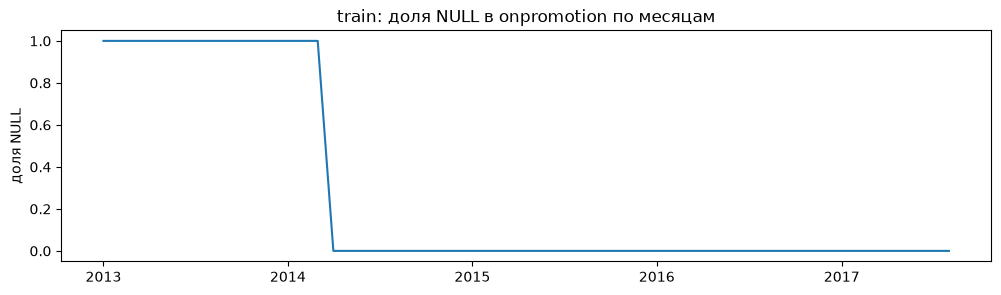

In [21]:
promo_null = q("""
SELECT
    date_trunc('month', date)                       AS month,
    COUNT(*)                                        AS n_rows,
    COUNT(*) FILTER (WHERE onpromotion IS NULL)     AS n_null,
    n_null / n_rows                                 AS share_null
FROM train
GROUP BY month
ORDER BY month
""")

fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(promo_null["month"], promo_null["share_null"])
ax.set_title("train: доля NULL в onpromotion по месяцам")
ax.set_ylabel("доля NULL")
plt.show()

In [22]:
q("""
SELECT
    MIN(date) FILTER (WHERE onpromotion IS NULL)                     AS first_null_date,
    MAX(date) FILTER (WHERE onpromotion IS NULL)                     AS last_null_date,
    MIN(date) FILTER (WHERE onpromotion IS NOT NULL)                 AS first_notnull_date,
    (SELECT COUNT(*) FILTER (WHERE onpromotion IS NULL) FROM test)   AS n_null_test,
    (SELECT COUNT(*) FROM test)                                      AS n_rows_test
FROM train
""")

,first_null_date,last_null_date,first_notnull_date,n_null_test,n_rows_test
0,2013-01-01,2014-03-31,2014-04-01,0,3370464


In [23]:
# Внутри переходного месяца: NULL зависит от даты или от магазина?
q("""
SELECT date, COUNT(*) AS n_rows, AVG((onpromotion IS NULL)::INT) AS share_null
FROM train
WHERE date BETWEEN (SELECT MAX(date) FROM train WHERE onpromotion IS NULL) - INTERVAL 10 DAY
               AND (SELECT MAX(date) FROM train WHERE onpromotion IS NULL) + INTERVAL 3 DAY
GROUP BY date
ORDER BY date
""")

,date,n_rows,share_null
0,2014-03-21,63610,1.0
1,2014-03-22,67983,1.0
2,2014-03-23,66562,1.0
3,2014-03-24,63337,1.0
4,2014-03-25,62650,1.0
5,2014-03-26,62774,1.0
6,2014-03-27,61580,1.0
7,2014-03-28,63426,1.0
8,2014-03-29,68879,1.0
9,2014-03-30,67532,1.0


### 3.2 Пропуски в oil: только выходные или и будни

Строим полный календарь на диапазоне oil и разделяем два вида пропусков:
нет строки за дату и строка есть, но `dcoilwtico` NULL.

In [24]:
oil_gaps = q("""
WITH cal AS (
    SELECT CAST(ts AS DATE) AS date
    FROM range(
        (SELECT MIN(date) FROM oil)::TIMESTAMP,
        (SELECT MAX(date) FROM oil)::TIMESTAMP + INTERVAL 1 DAY,
        INTERVAL 1 DAY
    ) AS r(ts)
)
SELECT
    c.date,
    dayname(c.date)              AS dow,
    isodow(c.date) >= 6          AS is_weekend,
    o.date IS NULL               AS row_missing,
    o.dcoilwtico IS NULL         AS value_null
FROM cal c
LEFT JOIN oil o USING (date)
WHERE o.date IS NULL OR o.dcoilwtico IS NULL
ORDER BY c.date
""")

oil_gaps[["is_weekend", "row_missing"]].value_counts().sort_index().reset_index(name="n_dates")

,is_weekend,row_missing,n_dates
0,False,False,43
1,True,True,486


In [25]:
# Будничные пропуски: совпадают ли они с национальными праздниками (у нефти — праздники США,
# так что совпадений с эквадорскими может и не быть)
weekday_gaps = oil_gaps.query("not is_weekend")
con.register("weekday_gaps", weekday_gaps)
q("""
SELECT g.date, g.dow, g.row_missing, g.value_null,
       STRING_AGG(h.description, '; ') AS ec_national_holiday
FROM weekday_gaps g
LEFT JOIN holidays_events h ON h.date = g.date AND h.locale = 'National'
GROUP BY ALL
ORDER BY g.date
""")

,date,dow,row_missing,value_null,ec_national_holiday
0,2013-01-01,Tuesday,False,True,Primer dia del ano
1,2013-01-21,Monday,False,True,NaN
2,2013-02-18,Monday,False,True,NaN
3,2013-03-29,Friday,False,True,NaN
4,2013-05-27,Monday,False,True,NaN
5,2013-07-04,Thursday,False,True,NaN
6,2013-09-02,Monday,False,True,NaN
7,2013-11-28,Thursday,False,True,NaN
8,2013-12-25,Wednesday,False,True,Navidad
9,2014-01-01,Wednesday,False,True,Primer dia del ano


In [26]:
# Покрывает ли oil весь период train + test
q("""
SELECT
    (SELECT MIN(date) FROM oil)   AS oil_min,  (SELECT MAX(date) FROM oil)   AS oil_max,
    (SELECT MIN(date) FROM train) AS train_min, (SELECT MAX(date) FROM test)  AS test_max
""")

,oil_min,oil_max,train_min,test_max
0,2013-01-01,2017-08-31,2013-01-01,2017-08-31


### 3.3 Пары (date, store_nbr): есть в train, но нет в transactions, и наоборот

Сравнение только на общем диапазоне дат, чтобы не считать «пропусками» края таблиц.
Для пар «только в train» дополнительно смотрим объём продаж: если там почти одни
возвраты/копейки — это одна история, если полноценные продажи — другая.

In [27]:
con.execute("""
CREATE OR REPLACE TEMP TABLE pairs_train AS
SELECT date, store_nbr, COUNT(*) AS n_items, SUM(unit_sales) AS sales
FROM train GROUP BY date, store_nbr
""")
con.execute("""
CREATE OR REPLACE TEMP TABLE pairs_tx AS
SELECT DISTINCT date, store_nbr FROM transactions
""")
con.execute("""
CREATE OR REPLACE TEMP VIEW common_range AS
SELECT GREATEST((SELECT MIN(date) FROM pairs_train), (SELECT MIN(date) FROM pairs_tx)) AS d_from,
       LEAST   ((SELECT MAX(date) FROM pairs_train), (SELECT MAX(date) FROM pairs_tx)) AS d_to
""")

q("""
SELECT 'train_only' AS side, COUNT(*) AS n_pairs
FROM pairs_train p, common_range r
WHERE p.date BETWEEN r.d_from AND r.d_to
  AND NOT EXISTS (SELECT 1 FROM pairs_tx x WHERE x.date = p.date AND x.store_nbr = p.store_nbr)
UNION ALL
SELECT 'transactions_only', COUNT(*)
FROM pairs_tx p, common_range r
WHERE p.date BETWEEN r.d_from AND r.d_to
  AND NOT EXISTS (SELECT 1 FROM pairs_train x WHERE x.date = p.date AND x.store_nbr = p.store_nbr)
""")

,side,n_pairs
0,train_only,118
1,transactions_only,0


In [28]:
# train_only: объём продаж в этих парах
train_only = q("""
SELECT p.*
FROM pairs_train p, common_range r
WHERE p.date BETWEEN r.d_from AND r.d_to
  AND NOT EXISTS (SELECT 1 FROM pairs_tx x WHERE x.date = p.date AND x.store_nbr = p.store_nbr)
ORDER BY date, store_nbr
""")
train_only.describe()

,date,store_nbr,n_items,sales
count,118,118.000000,118.000000,118.000000
mean,2015-11-25 13:13:13.220339,24.694915,1818.855932,20186.728269
min,2013-06-19 00:00:00,1.000000,387.000000,1699.048000
25%,2016-01-03 00:00:00,11.000000,1469.250000,10200.253250
50%,2016-01-03 00:00:00,21.500000,1864.500000,15821.157500
75%,2016-01-04 00:00:00,39.750000,2162.750000,23015.803500
max,2016-09-27 00:00:00,54.000000,2599.000000,74597.099000
std,NaN,15.958551,485.239165,15027.452240


In [29]:
# train_only по магазинам
q("""
SELECT p.store_nbr, COUNT(*) AS n_pairs, MIN(p.date) AS first_date, MAX(p.date) AS last_date,
       SUM(p.sales) AS sales
FROM pairs_train p, common_range r
WHERE p.date BETWEEN r.d_from AND r.d_to
  AND NOT EXISTS (SELECT 1 FROM pairs_tx x WHERE x.date = p.date AND x.store_nbr = p.store_nbr)
GROUP BY p.store_nbr
ORDER BY n_pairs DESC
LIMIT 20
""")

,store_nbr,n_pairs,first_date,last_date,sales
0,10,4,2013-06-19,2016-01-04,31857.513
1,7,4,2016-01-02,2016-09-27,94328.140
2,11,3,2016-01-02,2016-01-04,83870.810
3,25,3,2014-03-24,2016-01-03,33459.445
4,14,3,2016-01-02,2016-01-04,29479.985
5,3,3,2016-01-02,2016-01-04,151383.683
6,12,3,2016-01-02,2016-01-04,29955.047
7,6,3,2016-01-02,2016-01-04,77646.254
8,17,3,2016-01-02,2016-01-04,53649.951
9,4,3,2016-01-02,2016-01-04,55246.392


In [30]:
# transactions_only: по магазинам
q("""
SELECT p.store_nbr, COUNT(*) AS n_pairs, MIN(p.date) AS first, MAX(p.date) AS last
FROM pairs_tx p, common_range r
WHERE p.date BETWEEN r.d_from AND r.d_to
  AND NOT EXISTS (SELECT 1 FROM pairs_train x WHERE x.date = p.date AND x.store_nbr = p.store_nbr)
GROUP BY p.store_nbr
ORDER BY n_pairs DESC
""")

,store_nbr,n_pairs,first,last


### 3.4 Отсутствующие даты в train и transactions

Ожидание: в обеих нет 25.12 каждого года; в transactions — ещё 2 даты.

In [31]:
def missing_dates(table: str) -> pd.DataFrame:
    return q(f"""
    WITH cal AS (
        SELECT CAST(ts AS DATE) AS date
        FROM range((SELECT MIN(date) FROM {table})::TIMESTAMP,
                   (SELECT MAX(date) FROM {table})::TIMESTAMP + INTERVAL 1 DAY,
                   INTERVAL 1 DAY) AS r(ts)
    )
    SELECT '{table}' AS table_name, c.date, dayname(c.date) AS dow
    FROM cal c ANTI JOIN (SELECT DISTINCT date FROM {table}) t USING (date)
    ORDER BY c.date
    """)


pd.concat(
    [missing_dates("train"), missing_dates("transactions"), missing_dates("test")],
    ignore_index=True,
)

,table_name,date,dow
0,train,2013-12-25,Wednesday
1,train,2014-12-25,Thursday
2,train,2015-12-25,Friday
3,train,2016-12-25,Sunday
4,transactions,2013-12-25,Wednesday
5,transactions,2014-12-25,Thursday
6,transactions,2015-12-25,Friday
7,transactions,2016-01-01,Friday
8,transactions,2016-01-03,Sunday
9,transactions,2016-12-25,Sunday


## 4. Валидность

### 4.1 unit_sales < 0: число, доля, по каким семействам

In [32]:
q("""
SELECT
    COUNT(*)                                       AS n_rows,
    COUNT(*) FILTER (WHERE unit_sales < 0)         AS n_negative,
    n_negative / n_rows                            AS share_negative,
    SUM(unit_sales) FILTER (WHERE unit_sales < 0)  AS sum_negative,
    MIN(unit_sales)                                AS min_sales
FROM train
""")

,n_rows,n_negative,share_negative,sum_negative,min_sales
0,125497040,7795,0.000062,-143580.8275,-15372.0


In [33]:
q("""
WITH neg AS (SELECT item_nbr, unit_sales FROM train WHERE unit_sales < 0),
     fam_rows AS (
        SELECT i.family, COUNT(*) AS n_rows_family
        FROM train t JOIN items i USING (item_nbr)
        GROUP BY i.family
     )
SELECT
    i.family,
    COUNT(*)                                     AS n_negative,
    n_negative / SUM(COUNT(*)) OVER ()           AS share_of_all_negative,
    n_negative / ANY_VALUE(f.n_rows_family)      AS share_within_family,
    SUM(n.unit_sales)                            AS sum_negative,
    COUNT(DISTINCT n.item_nbr)                   AS n_items
FROM neg n
JOIN items i USING (item_nbr)
JOIN fam_rows f USING (family)
GROUP BY i.family
ORDER BY n_negative DESC
""")

,family,n_negative,share_of_all_negative,share_within_family,sum_negative,n_items
0,GROCERY I,2160,0.277101,0.000047,-50015.5270,835
1,BEVERAGES,1361,0.174599,0.000077,-42782.0000,395
2,CLEANING,1026,0.131623,0.000060,-11920.0000,307
3,PERSONAL CARE,401,0.051443,0.000089,-14688.0000,116
4,DAIRY,380,0.048749,0.000042,-2962.0000,142
5,PRODUCE,302,0.038743,0.000042,-1845.4320,129
6,HOME AND KITCHEN II,203,0.026042,0.000419,-448.0000,29
7,BREAD/BAKERY,194,0.024888,0.000042,-1468.0000,80
8,HOME AND KITCHEN I,179,0.022963,0.000319,-896.0000,57
9,HOME CARE,154,0.019756,0.000053,-3587.0000,63


### 4.2 unit_sales = 0: есть ли вообще

In [34]:
q("""
SELECT
    COUNT(*) FILTER (WHERE unit_sales = 0)                        AS n_zero,
    COUNT(*) FILTER (WHERE unit_sales IS NULL)                    AS n_null,
    COUNT(*) FILTER (WHERE unit_sales <> 0 AND ABS(unit_sales) < 1e-3) AS n_near_zero
FROM train
""")

,n_zero,n_null,n_near_zero
0,0,0,0


### 4.3 Дробные unit_sales у штучных товаров

В `items` нет признака «весовой товар» (`perishable` — это скоропортящийся, не весовой).
Поэтому признак выводится из данных: для каждого товара считаем долю строк с дробными
продажами. Весовые товары дают дробь почти всегда, штучные — никогда. Подозрительны
товары с малой, но ненулевой долей дробей.

товаров всего: 4036, с хотя бы одной дробной продажей: 294


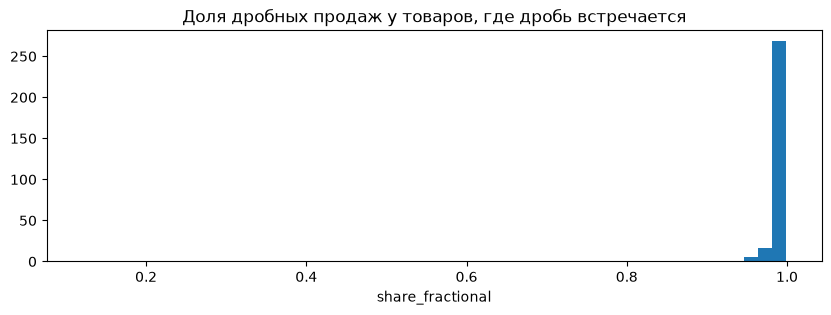

In [35]:
EPS = 1e-6

frac_by_item = q(f"""
SELECT
    t.item_nbr,
    ANY_VALUE(i.family)                                                    AS family,
    ANY_VALUE(i.perishable)                                                AS perishable,
    COUNT(*)                                                               AS n_rows,
    COUNT(*) FILTER (WHERE ABS(unit_sales - ROUND(unit_sales)) > {EPS})    AS n_fractional,
    n_fractional / n_rows                                                  AS share_fractional
FROM train t
LEFT JOIN items i USING (item_nbr)
GROUP BY t.item_nbr
""")

has_frac = frac_by_item.query("n_fractional > 0")
print(f"товаров всего: {len(frac_by_item)}, с хотя бы одной дробной продажей: {len(has_frac)}")

fig, ax = plt.subplots(figsize=(10, 3))
ax.hist(has_frac["share_fractional"], bins=50)
ax.set_title("Доля дробных продаж у товаров, где дробь встречается")
ax.set_xlabel("share_fractional")
plt.show()

In [36]:
# Распределение по семействам: где живут «весовые» товары
LOW, HIGH = 0.05, 0.5  # пороги: ниже LOW — подозрительно, выше HIGH — весовой

frac_by_item["kind"] = pd.cut(
    frac_by_item["share_fractional"],
    bins=[-0.001, 0, LOW, HIGH, 1.0],
    labels=["integer_only", "suspicious", "mixed", "weight_like"],
)
print(frac_by_item["kind"].value_counts(sort=False).to_dict())

# dropna=False: без него crosstab выбрасывает пустые категории, и sort_values падает с KeyError
pd.crosstab(frac_by_item["family"], frac_by_item["kind"], dropna=False).sort_values(
    ["suspicious", "mixed"], ascending=False
)

{'integer_only': 3742, 'suspicious': 0, 'mixed': 1, 'weight_like': 293}


kind,integer_only,suspicious,mixed,weight_like
family,,,,
MEATS,1,0,1,82
AUTOMOTIVE,20,0,0,0
BABY CARE,1,0,0,0
BEAUTY,19,0,0,0
BEVERAGES,604,0,0,0
BOOKS,1,0,0,0
BREAD/BAKERY,133,0,0,1
CELEBRATION,31,0,0,0
CLEANING,446,0,0,0


In [37]:
# Примеры дробных значений у подозрительных товаров
suspicious = frac_by_item.query("kind == 'suspicious'")[["item_nbr"]]
con.register("suspicious_items", suspicious)
q(f"""
SELECT t.item_nbr, i.family, t.date, t.store_nbr, t.unit_sales
FROM train t
JOIN suspicious_items s USING (item_nbr)
JOIN items i USING (item_nbr)
WHERE ABS(t.unit_sales - ROUND(t.unit_sales)) > {EPS}
ORDER BY t.item_nbr, t.date
LIMIT 100
""")

,item_nbr,family,date,store_nbr,unit_sales


### 4.4 Выбросы: верхние квантили, самые большие значения и их даты

Квантили — приближённые (`approx_quantile`), на 125 млн строк точные считаются заметно дольше.

In [38]:
q("""
SELECT
    approx_quantile(unit_sales, 0.5)     AS p50,
    approx_quantile(unit_sales, 0.9)     AS p90,
    approx_quantile(unit_sales, 0.99)    AS p99,
    approx_quantile(unit_sales, 0.999)   AS p999,
    approx_quantile(unit_sales, 0.9999)  AS p9999,
    MAX(unit_sales)                      AS max
FROM train
WHERE unit_sales > 0
""")

,p50,p90,p99,p999,p9999,max
0,4.0,18.411285,71.679055,228.112494,732.983715,89440.0


In [39]:
# Топ-30 значений с контекстом
q("""
SELECT t.date, dayname(t.date) AS dow, t.store_nbr, t.item_nbr, i.family,
       t.unit_sales, t.onpromotion
FROM train t
LEFT JOIN items i USING (item_nbr)
ORDER BY t.unit_sales DESC
LIMIT 30
""")

,date,dow,store_nbr,item_nbr,family,unit_sales,onpromotion
0,2016-10-07,Friday,39,1976284,MEATS,89440.000,False
1,2016-04-21,Thursday,20,841842,GROCERY I,44142.000,False
2,2016-05-02,Monday,2,1162932,GROCERY I,30000.000,False
3,2016-04-18,Monday,45,559870,GROCERY I,20748.000,False
4,2016-05-02,Monday,2,305227,GROCERY I,20000.000,False
5,2017-04-12,Wednesday,32,1963892,GROCERY I,17146.000,True
6,2016-04-21,Thursday,20,1464133,BEVERAGES,16000.000,False
7,2017-06-25,Sunday,54,2013931,BEVERAGES,15375.000,False
8,2016-04-26,Tuesday,2,1162932,GROCERY I,15000.000,False
9,2017-04-02,Sunday,9,754103,GROCERY I,14483.000,False


In [40]:
# Выбросы относительно самого товара: продажа > 20 медиан этого товара в этом магазине
q("""
WITH med AS (
    SELECT store_nbr, item_nbr, MEDIAN(unit_sales) AS med_sales
    FROM train WHERE unit_sales > 0
    GROUP BY store_nbr, item_nbr
)
SELECT t.date, COUNT(*) AS n_extreme
FROM train t JOIN med m USING (store_nbr, item_nbr)
WHERE t.unit_sales > 20 * m.med_sales AND m.med_sales >= 1
GROUP BY t.date
ORDER BY n_extreme DESC
LIMIT 20
""")

,date,n_extreme
0,2016-04-18,658
1,2016-12-23,521
2,2016-12-24,515
3,2016-04-19,505
4,2016-12-22,488
5,2015-12-22,478
6,2014-12-23,469
7,2014-12-24,438
8,2016-12-21,431
9,2015-12-24,431


## 5. Покрытие во времени

### 5.1 Магазины: первая и последняя дата продаж, периоды «молчания»

Границы считаются по **торговым дням** — датам, когда работает не меньше `MIN_STORE_SHARE`
магазинов. 25.12 в train нет, а 1 января торгуют 1–2 магазина; если его не исключить,
началом истории станет 2013-01-01, и почти все магазины ложно попадут в «поздно открывшиеся».

Позднее открытие — `first_date` позже первого торгового дня; закрытие — `last_date` раньше
последнего; `n_days_missing` — торговые дни внутри периода магазина без продаж;
молчание — разрыв между соседними датами продаж больше `GAP_DAYS`.

In [ ]:
GAP_DAYS = 7
# Торговый день — дата, когда работает не меньше этой доли магазинов. Отсекает 1 января:
# в этот день торгуют 1–2 магазина, и без фильтра границы истории сдвигаются на 2013-01-01.
MIN_STORE_SHARE = 0.5

store_span = q(f"""
WITH d AS (SELECT DISTINCT store_nbr, date FROM train),
     trading_days AS (
        SELECT date FROM d GROUP BY date
        HAVING COUNT(*) >= {MIN_STORE_SHARE} * (SELECT COUNT(DISTINCT store_nbr) FROM d)
     ),
     bounds AS (SELECT MIN(date) AS gmin, MAX(date) AS gmax FROM trading_days),
     s AS (
        SELECT store_nbr, MIN(date) AS first_date, MAX(date) AS last_date,
               COUNT(*) AS n_days_with_sales
        FROM d SEMI JOIN trading_days USING (date)
        GROUP BY store_nbr
     ),
     spans AS (
        SELECT s.store_nbr, COUNT(*) AS n_trading_days_span
        FROM s JOIN trading_days td ON td.date BETWEEN s.first_date AND s.last_date
        GROUP BY s.store_nbr
     )
SELECT
    s.store_nbr,
    s.first_date,
    s.last_date,
    s.n_days_with_sales,
    p.n_trading_days_span,
    p.n_trading_days_span - s.n_days_with_sales  AS n_days_missing,
    s.first_date > b.gmin                        AS opened_late,
    s.last_date < b.gmax                         AS closed_early
FROM s
JOIN spans p USING (store_nbr)
CROSS JOIN bounds b
ORDER BY s.store_nbr
""")
store_span.query("opened_late or closed_early or n_days_missing > 0")

In [42]:
q(f"""
WITH d AS (SELECT DISTINCT store_nbr, date FROM train),
     g AS (
        SELECT store_nbr, date,
               LAG(date) OVER (PARTITION BY store_nbr ORDER BY date) AS prev_date
        FROM d
     )
SELECT store_nbr, prev_date AS silent_from, date AS silent_to,
       datediff('day', prev_date, date) - 1 AS n_silent_days
FROM g
WHERE datediff('day', prev_date, date) > {GAP_DAYS}
ORDER BY n_silent_days DESC
""")

,store_nbr,silent_from,silent_to,n_silent_days
0,18,2016-08-14,2016-12-03,110
1,24,2014-04-13,2014-07-24,101
2,25,2016-08-21,2016-10-27,66
3,12,2015-03-29,2015-05-29,60
4,14,2014-08-03,2014-09-11,38
5,30,2013-07-07,2013-07-31,23


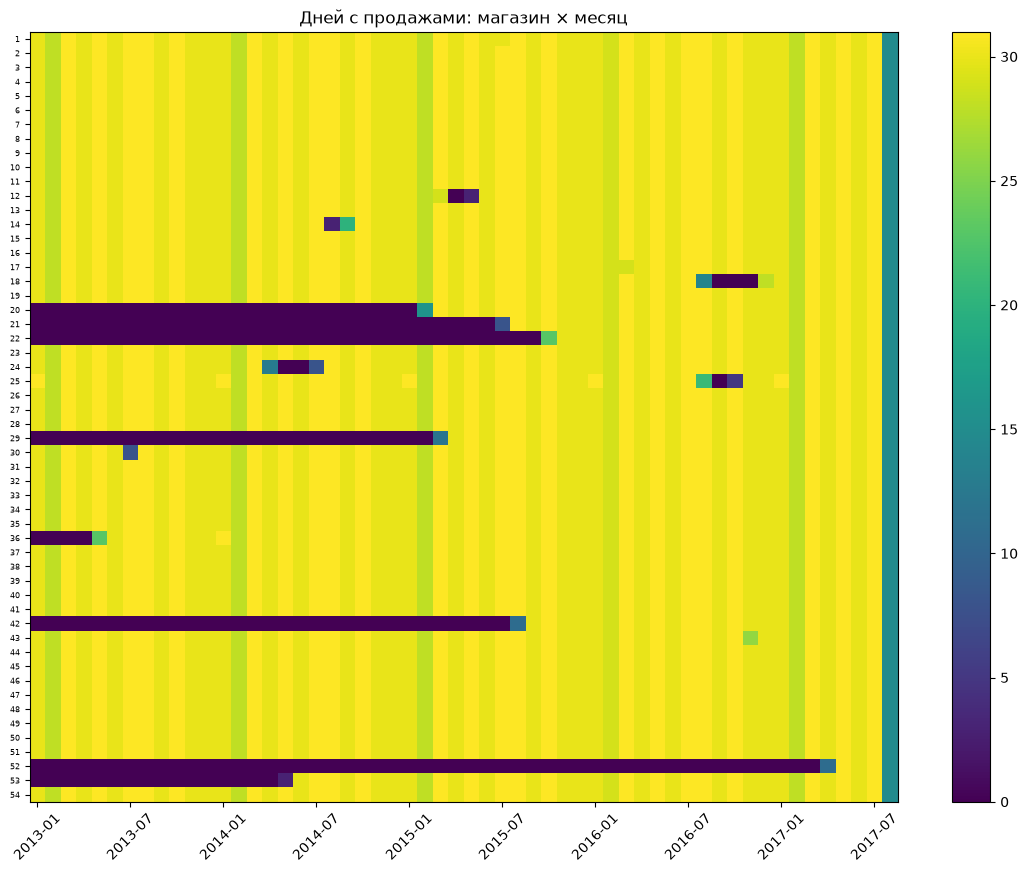

In [43]:
# Тепловая карта: число дней с продажами по магазину и месяцу
heat = (
    q("""
SELECT store_nbr, date_trunc('month', date) AS month, COUNT(DISTINCT date) AS n_days
FROM train GROUP BY ALL
""")
    .pivot(index="store_nbr", columns="month", values="n_days")
    .fillna(0)
)

fig, ax = plt.subplots(figsize=(14, 10))
im = ax.imshow(heat.values, aspect="auto", cmap="viridis")
ax.set_yticks(range(len(heat.index)), heat.index, fontsize=6)
step = 6
ax.set_xticks(
    range(0, len(heat.columns), step),
    [c.strftime("%Y-%m") for c in heat.columns[::step]],
    rotation=45,
)
ax.set_title("Дней с продажами: магазин × месяц")
fig.colorbar(im, ax=ax)
plt.show()

### 5.2 Товары: когда появился и когда исчез

In [44]:
item_span = q("""
WITH bounds AS (SELECT MIN(date) AS gmin, MAX(date) AS gmax FROM train)
SELECT
    t.item_nbr,
    MIN(t.date)                       AS first_date,
    MAX(t.date)                       AS last_date,
    COUNT(DISTINCT t.date)            AS n_days_with_sales,
    ANY_VALUE(b.gmin)                 AS gmin,
    ANY_VALUE(b.gmax)                 AS gmax
FROM train t, bounds b
GROUP BY t.item_nbr
""")

LATE_DAYS = 30
item_span["appeared_late"] = (item_span["first_date"] - item_span["gmin"]).dt.days > LATE_DAYS
item_span["disappeared_early"] = (item_span["gmax"] - item_span["last_date"]).dt.days > LATE_DAYS
item_span[["appeared_late", "disappeared_early"]].value_counts().sort_index().reset_index(
    name="n_items"
)

,appeared_late,disappeared_early,n_items
0,False,False,1569
1,False,True,48
2,True,False,2305
3,True,True,114


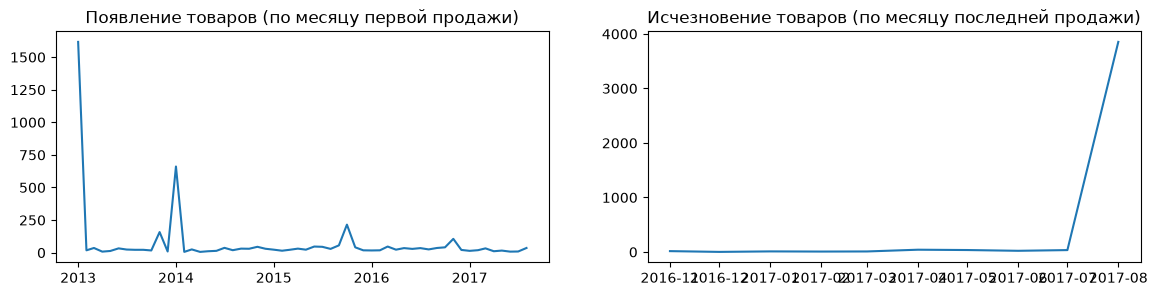

In [45]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3))
for axis, col, title in [
    (axes[0], "first_date", "Появление товаров (по месяцу первой продажи)"),
    (axes[1], "last_date", "Исчезновение товаров (по месяцу последней продажи)"),
]:
    by_month = item_span[col].dt.to_period("M").dt.to_timestamp().value_counts().sort_index()
    axis.plot(by_month.index, by_month.to_numpy())
    axis.set_title(title)
plt.show()

In [46]:
# Товары, исчезнувшие задолго до конца train, но присутствующие в test
gone = item_span.query("disappeared_early")[["item_nbr"]]
con.register("gone_items", gone)
scalar("SELECT COUNT(*) FROM gone_items WHERE item_nbr IN (SELECT DISTINCT item_nbr FROM test)")

5

### 5.3 Число строк train по дням: плавный рост или скачки

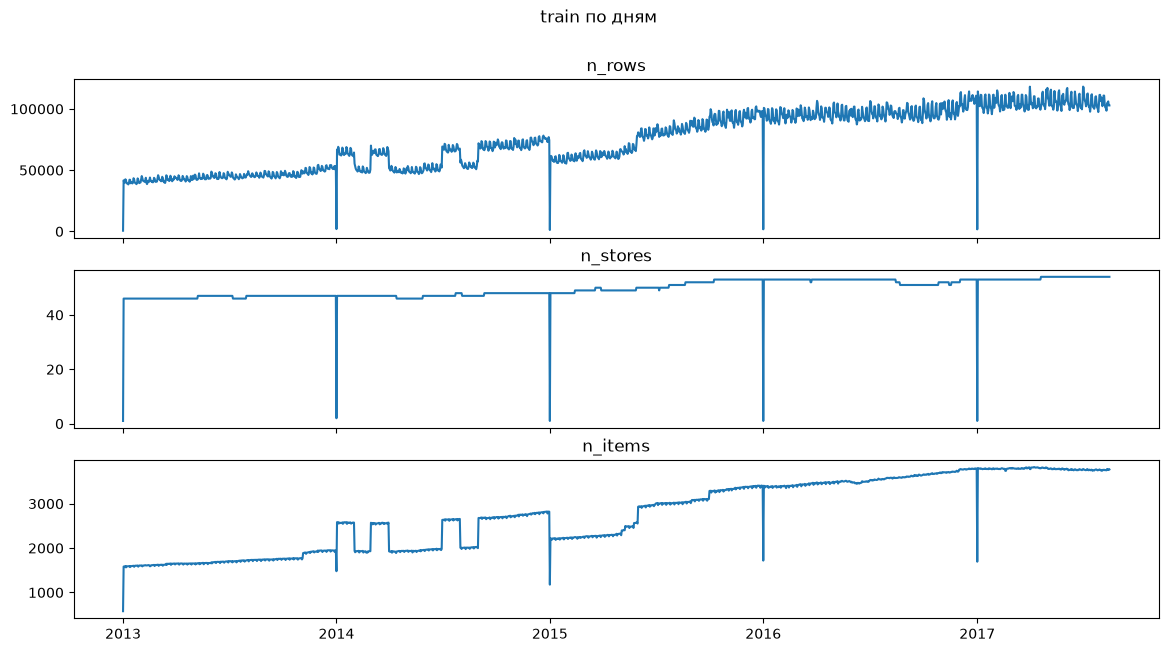

In [47]:
daily = q("""
SELECT date, COUNT(*) AS n_rows, COUNT(DISTINCT store_nbr) AS n_stores,
       COUNT(DISTINCT item_nbr) AS n_items
FROM train GROUP BY date ORDER BY date
""").set_index("date")

fig, axes = plt.subplots(3, 1, figsize=(14, 7), sharex=True)
for axis, col in zip(axes, ["n_rows", "n_stores", "n_items"], strict=True):
    axis.plot(daily.index, daily[col])
    axis.set_title(col)
fig.suptitle("train по дням")
plt.show()

In [48]:
# Самые резкие изменения день к дню (без учёта пропущенных 25.12)
jumps = daily.copy()
jumps["delta"] = jumps["n_rows"].diff()
jumps["rel_delta"] = jumps["n_rows"].pct_change()
jumps["abs_rel_delta"] = jumps["rel_delta"].abs()
jumps.sort_values("abs_rel_delta", ascending=False).head(15)

,n_rows,n_stores,n_items,delta,rel_delta,abs_rel_delta
date,,,,,,
2013-01-02,41676,46,1583,41098.0,71.103806,71.103806
2017-01-02,114225,53,3800,112532.0,66.468990,66.468990
2016-01-02,100830,53,3404,99112.0,57.690338,57.690338
2015-01-02,60938,48,2215,59762.0,50.818027,50.818027
2014-01-02,66819,47,2584,64908.0,33.965463,33.965463
2017-01-01,1693,1,1693,-108605.0,-0.984651,0.984651
2015-01-01,1176,1,1176,-73288.0,-0.984207,0.984207
2016-01-01,1718,1,1718,-94971.0,-0.982232,0.982232
2014-01-01,1911,2,1479,-48739.0,-0.962270,0.962270


## 6. Согласованность между train и test

### 6.1 Одни ли и те же магазины

In [49]:
TRAIN_RECENT_FROM = "2017-07-01"  # «живые» магазины на конец train


def store_set(sql: str) -> set[int]:
    return {int(row[0]) for row in con.sql(sql).fetchall()}


stores_train = store_set("SELECT DISTINCT store_nbr FROM train")
stores_recent = store_set(
    f"SELECT DISTINCT store_nbr FROM train WHERE date >= '{TRAIN_RECENT_FROM}'"
)
stores_test = store_set("SELECT DISTINCT store_nbr FROM test")

{
    "train": len(stores_train),
    "test": len(stores_test),
    "test, но не в train": sorted(stores_test - stores_train),
    "train, но не в test": sorted(stores_train - stores_test),
    f"test, но без продаж с {TRAIN_RECENT_FROM}": sorted(stores_test - stores_recent),
}

{'train': 54,
 'test': 54,
 'test, но не в train': [],
 'train, но не в test': [],
 'test, но без продаж с 2017-07-01': []}

### 6.2 Полная ли сетка в test (строк = даты × магазины × товары)

In [50]:
q("""
SELECT
    COUNT(*)                                          AS n_rows,
    COUNT(DISTINCT date)                              AS n_dates,
    COUNT(DISTINCT store_nbr)                         AS n_stores,
    COUNT(DISTINCT item_nbr)                          AS n_items,
    n_dates * n_stores * n_items                      AS n_full_grid,
    (SELECT COUNT(*) FROM (SELECT DISTINCT date, store_nbr, item_nbr FROM test)) AS n_distinct_keys,
    COUNT(DISTINCT id)                                AS n_distinct_id
FROM test
""")

,n_rows,n_dates,n_stores,n_items,n_full_grid,n_distinct_keys,n_distinct_id
0,3370464,16,54,3901,3370464,3370464,3370464


In [51]:
# Если сетка неполная — где дыры: число строк по дате и по магазину
q("SELECT date, COUNT(*) AS n_rows FROM test GROUP BY date ORDER BY date")

,date,n_rows
0,2017-08-16,210654
1,2017-08-17,210654
2,2017-08-18,210654
3,2017-08-19,210654
4,2017-08-20,210654
5,2017-08-21,210654
6,2017-08-22,210654
7,2017-08-23,210654
8,2017-08-24,210654
9,2017-08-25,210654


In [52]:
q("""
SELECT store_nbr, COUNT(*) AS n_rows
FROM test GROUP BY store_nbr
HAVING COUNT(*) <> (SELECT MAX(c) FROM (SELECT COUNT(*) AS c FROM test GROUP BY store_nbr))
ORDER BY store_nbr
""")

,store_nbr,n_rows


### 6.3 Распределение onpromotion в test против последних месяцев train

Сравнение «как есть» смещено: train содержит только строки с ненулевыми продажами,
а test — полную сетку (включая товары, которые в этот день не продались бы).
Доля промо в test поэтому ожидаемо ниже. NULL в train исключены.

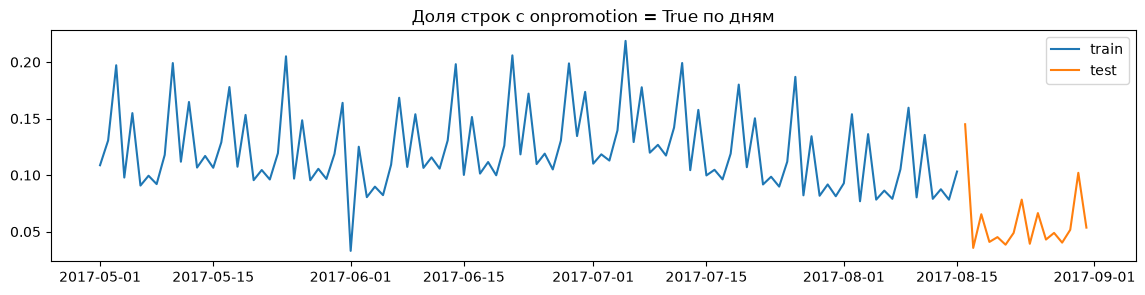

,count,mean,std,min,25%,50%,75%,max
part,,,,,,,,
test,16.0,0.058923,0.028849,0.035627,0.040743,0.048876,0.065655,0.144972
train,107.0,0.122292,0.035963,0.032979,0.097374,0.111839,0.140836,0.218696


In [53]:
TRAIN_FROM = "2017-05-01"

promo = q(f"""
SELECT 'train' AS part, date, AVG(onpromotion::BOOLEAN::INT) AS share_promo, COUNT(*) AS n_rows
FROM train
WHERE date >= '{TRAIN_FROM}' AND onpromotion IS NOT NULL
GROUP BY date
UNION ALL
SELECT 'test', date, AVG(onpromotion::BOOLEAN::INT), COUNT(*)
FROM test
GROUP BY date
ORDER BY date
""")

fig, ax = plt.subplots(figsize=(14, 3))
for part in ["train", "test"]:
    g = promo[promo["part"] == part]
    ax.plot(g["date"], g["share_promo"], label=part)
ax.set_title("Доля строк с onpromotion = True по дням")
ax.legend()
plt.show()

promo.groupby("part")["share_promo"].describe()

In [54]:
# Сопоставимое сравнение: в train достраиваем сетку до (дата × магазин × товар) на последних
# 16 днях — пропущенная строка = промо неизвестно, поэтому сравниваем долю промо среди
# всех пар магазин×товар, которые были в test
q("""
WITH last_days AS (
    SELECT DISTINCT date FROM train
    WHERE date > (SELECT MAX(date) FROM train) - INTERVAL 16 DAY
),
grid AS (
    SELECT d.date, p.store_nbr, p.item_nbr
    FROM last_days d, (SELECT DISTINCT store_nbr, item_nbr FROM test) p
)
SELECT
    COUNT(*)                                                   AS n_grid_rows,
    COUNT(t.item_nbr)                                          AS n_rows_with_sales,
    SUM(COALESCE(t.onpromotion::BOOLEAN::INT, 0)) / COUNT(*)   AS share_promo_on_grid,
    (SELECT AVG(onpromotion::BOOLEAN::INT) FROM test)          AS share_promo_test
FROM grid g
LEFT JOIN (
    SELECT date, store_nbr, item_nbr, onpromotion
    FROM train
    WHERE date IN (SELECT date FROM last_days)
) t USING (date, store_nbr, item_nbr)
""")

,n_grid_rows,n_rows_with_sales,share_promo_on_grid,share_promo_test
0,3370464,1676313,0.050103,0.058923


## Выводы

Колонка «Решение для silver» — **предложения**, а не принятые решения: окончательный выбор фиксируется в журнале решений.

| # | Проверка | Результат | Решение для silver (предложение) |
|---|---|---|---|
| 1.1 | UK transactions | 83 488 строк, 0 дублей, 0 NULL в ключе. UK (date, store_nbr) подтверждён | не требуется |
| 1.2 | Ключ holidays_events | Полных дублей нет. Минимальный ключ — (date, locale_name, description), 0 дублей. (date, locale_name) даёт 7 конфликтов: у одной территории в один день два события (Additional + Bridge, Holiday + Event, Additional + Transfer) | в `holiday_features` сворачивать события в (date, store_nbr) флагами по type, а не соединять строки |
| 2.1–2.2 | FK store/item | 0 сирот: store_nbr в train, test, transactions → stores; item_nbr в train, test → items. FK подтверждены | не требуется |
| 2.3 | Неиспользуемые записи справочников | Магазины: все 54 есть во всех фактах. Товары: 195 только в train, 60 только в test, 4 нигде (2 LIQUOR,WINE,BEER, 1 GROCERY I, 1 BEVERAGES) | 195 — вероятно, выведенные из ассортимента: для обучения годятся, прогноз не нужен. 4 — игнорировать |
| 2.4 | locale_name | Local ⊂ stores.city и Regional ⊂ stores.state без исключений. National — одно значение Ecuador (174 строки). Esmeraldas и Loja — одновременно город и провинция | соединять строго по правилу locale → поле. Соединение «по любому совпадению» дало бы для Esmeraldas и Loja ложные пары |
| 2.5 | Новые товары в test | 60 товаров (43 из них GROCERY I), 51 840 строк = 1,54 % test. Это ровно 60 × 54 × 16, то есть полная сетка | холодный старт: нужен отдельный fallback-прогноз (по class/family или 0) |
| 3.1 | NULL onpromotion | 21 657 651 строка. NULL — все строки с 2013-01-01 по 2014-03-31, с 2014-04-01 NULL нет; в test NULL нет. Граница проходит по дате, а не по магазину | NULL ≠ False: флаг `promo_known`. Эффект промо оценивать только на данных с 2014-04-01 |
| 3.2 | Пропуски oil | 486 дат без строки — все выходные. 43 будних дня: строка есть, значение NULL; это нерабочие дни бирж США (MLK Day, Presidents Day, Good Friday, Memorial Day, 4 июля, Labor Day, Thanksgiving, Рождество, Новый год), с праздниками Эквадора совпадают случайно. Первая же дата (2013-01-01) — NULL. Oil покрывает train и test | полный календарь, заполнение только из прошлого (ffill), флаг `is_imputed`. Для 2013-01-01 ffill невозможен: выбрать NULL или bfill одного дня и записать это в журнал |
| 3.3 | train vs transactions | На общем диапазоне transactions ⊂ train: 0 пар только в transactions, 118 пар только в train. В этих 118 парах обычные продажи (медиана 15,8 тыс. ед., 387–2599 товаров). Большинство пришлось на 2016-01-02…04, рядом с пропущенной в transactions датой 2016-01-03; остальные — единичные даты 2013-06-19…2016-09-27 | пропуск в transactions означает потерю записи, а не закрытый магазин: `transactions = NULL` и флаг, но не 0 |
| 3.4 | Отсутствующие даты | train: нет 25.12 за 2013–2016. transactions: те же даты и ещё 2016-01-01 и 2016-01-03. Также 1 января в train торгуют только 1–2 магазина из 54 (см. 5.3) | 25.12 исключить из календаря. 1 января считать днём закрытия для магазинов без продаж в эту дату и не восстанавливать для них нули |
| 4.1 | Отрицательные продажи | 7 795 строк (0,006 %), сумма −143 581, минимум −15 372. Встречаются во всех 32 семействах; наибольшая доля внутри семейства — в HOME APPLIANCES и BOOKS, но там это единицы строк | масштаб малый. Варианты для журнала: обнулить с флагом или вынести в отдельный столбец `returns`. Перед решением проверить, есть ли у крупных возвратов парная крупная продажа |
| 4.2 | Нулевые продажи | 0 строк с unit_sales = 0, NULL нет. Утверждение Kaggle подтверждено | отсутствие строки трактовать как 0, но только в окне активности ряда (см. 3.4, 5.1–5.3) |
| 4.3 | Дробные продажи | Дроби есть у 294 из 4 036 товаров. Распределение бимодальное: 293 «весовых» (дробных строк > 50 %), 1 смешанный (MEATS), подозрительных 0. Весовые товары сосредоточены в PRODUCE, MEATS, POULTRY, FROZEN FOODS, DELI | вывести признак `is_weighted`. В EDA-агрегатах не складывать без оговорки unit_sales весовых и штучных товаров: получится сумма килограммов и штук |
| 4.4 | Выбросы | p50 = 4, p99 = 72, p99.99 = 733, max = 89 440 (магазин 39, MEATS, 2016-10-07, в 122 раза выше p99.99). Выбросы двух видов. Точечные: 89 440 и круглые 30 000 / 20 000 / 15 000 в магазине 2. Событийные: массовые всплески 2016-04-18…21 (землетрясение 16.04) и 19–24 декабря каждого года. Крупнейшие значения апреля–мая 2016 тоже приходятся на дни после землетрясения | событийные — реальный спрос: оставить и пометить флагом события. Точечные — флаг `is_outlier`; что с ними делать (оставить, ограничить сверху, удалить), решается в журнале |
| 5.1 | Покрытие магазинов | Позже начала истории открылись 8 магазинов: 36 (2013-05-09), 53 (2014-05-29), 20, 29, 21, 42, 22 (2015), 52 (2017-04-20, всего 118 дней истории). Закрытых нет. Периоды без продаж > 7 дней у 6 магазинов: 18 (110 дней, 2016-08…12), 24 (101), 25 (66), 12 (60), 14 (38), 30 (23). Границы считаются по торговым дням (без 1 января), иначе почти все магазины ложно попадают в «поздно открывшиеся» | окно активности магазина начинается с первой продажи. Периоды молчания считать закрытием: нули не восстанавливать |
| 5.2 | Покрытие товаров | Весь период присутствуют 1 569 из 4 036 товаров. 2 419 появились позже (> 30 дней от начала), 162 исчезли раньше (> 30 дней до конца); из исчезнувших 5 есть в test | окно активности пары (магазин, товар) начинается с первой продажи. 5 «вернувшихся» товаров прогнозировать как холодный старт |
| 5.3 | Строк по дням | Рост с 41 тыс. до 114 тыс. строк в день в основном за счёт ассортимента (1 583 → 3 800 товаров). Скачки 1–2 января объясняются закрытием 1 января. **Не объяснены** скачки на границах месяцев в 2014 г.: 02 −14 %, 03 +39 %, 04 −21 %, 07 +33 %, 08 −17 %, 09 +26 %. Падение 2014-04-01 совпадает с концом NULL в onpromotion | открытый вопрос: проверить, не менялась ли в 2014 г. полнота записи ассортимента по месяцам. Если менялась, то в 2014 г. правило «нет строки = 0» неверно |
| 6.1 | Магазины train/test | Одни и те же 54 магазина, у всех есть продажи с 2017-07-01 | не требуется |
| 6.2 | Сетка test | Сетка полная: 16 × 54 × 3 901 = 3 370 464, ключ и id уникальны | прогноз строится для всей сетки |
| 6.3 | onpromotion train/test | Если сравнивать в лоб: train 12,2 %, test 5,9 %. Разница — артефакт отсутствия нулевых строк в train. На сетке последних 16 дней train доля 5,0 % против 5,9 % в test, то есть сопоставима | сдвига распределения нет. Промо связано с самим наличием строки в train, поэтому оценка эффекта промо по bronze без восстановления нулей будет завышена |

### Итог

1. **Структурная целостность в порядке.** Ключи transactions, FK store_nbr и item_nbr, правило locale_name → city/state и полнота сетки test подтверждены. Звёздочки на ER-схеме можно снять.
2. **Главная задача silver — восстановление нулей.** Нулей в train нет (4.2), поэтому отсутствие строки означает 0 продаж. Но так можно трактовать отсутствие строки только внутри окна активности ряда. Окно ограничивают 25.12 и 1 января (3.4), поздние открытия и периоды молчания магазинов (5.1), появление и исчезновение товаров (5.2).
3. **Главный открытый риск — 2014 год.** Скачки числа строк на границах месяцев (5.3) и граница NULL в onpromotion (3.1) указывают на смену способа записи данных. Пока это не проверено, данные до 2014-09 нельзя считать надёжными для восстановления нулей.
4. **Выбросы бывают двух видов**, и обрабатывать их нужно по-разному: событийные пики (землетрясение 2016-04, предрождественские дни) — реальный спрос; точечные значения вроде 89 440 — вероятные ошибки или оптовые закупки.
5. **Холодный старт** касается 1,5 % строк test (60 новых товаров), магазина 52 со 118 днями истории и 5 вернувшихся товаров. Для них нужна отдельная стратегия прогноза.
6. **Единицы измерения неоднородны:** у 293 товаров unit_sales — килограммы. Это важно для любых агрегатов в EDA.